<a href="https://colab.research.google.com/github/ShiaMicaNaomiOnix/Student-Grade-Measurement-Program-by-Python/blob/main/%ED%95%99%EC%83%9D_%EC%A0%90%EC%88%98_%EC%B0%BE%EA%B8%B0_%EB%B0%8F_%EA%B7%B8%EB%9E%98%ED%94%84_%EA%B7%B8%EB%A6%AC%EA%B8%B0_%ED%94%84%EB%A1%9C%EC%A0%9D%ED%8A%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#한글 폰트 설치
#한글 폰트 구글 코랩 한글깨짐 현상 해결방법
#https://teddylee777.github.io/colab/colab-korean/
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 35 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (8,767 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 126111 files and dire

In [ ]:
import matplotlib.pyplot as plt

plt.rc('font', family='NanumBarunGothic')

학생 번호를 입력하세요 (0부터 시작): 7


<ipython-input-4-1935c0172e23>:54: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


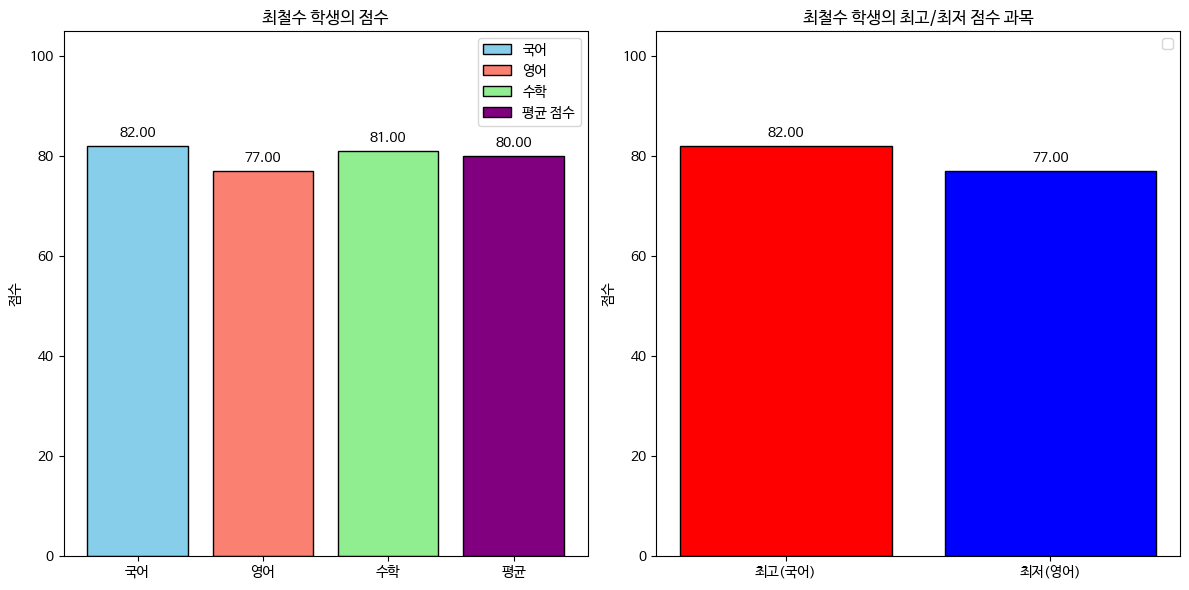

In [ ]:
#학생 점수 찾기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# CSV 읽기
grade = pd.read_csv('student_scores_clear_utf8.csv', encoding='utf-8-sig')
grade.dropna(inplace=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# 평균 점수 컬럼 추가
grade["평균"] = (grade["국어"] + grade["영어"] + grade["수학"]) / 3

# 특정 학생 번호 입력
student_index = int(input("학생 번호를 입력하세요 (0부터 시작): "))

# 학생 정보
subjects = ['국어', '영어', '수학']
scores = grade.loc[student_index, subjects].values
avg_score = grade.loc[student_index, '평균']

# 그래프1
#첫 번째 그래프 - 학생의 과목 점수 & 평균 보여주기
bars1 = ax[0].bar(subjects, scores, color=['skyblue', 'salmon', 'lightgreen'], edgecolor='black', label=['국어', '영어', '수학'])
avg_bar = ax[0].bar(['평균'], avg_score, color='purple', edgecolor='black', label='평균 점수')
ax[0].set_ylim(0, 105)
ax[0].set_title(f"{grade.loc[student_index, '이름']} 학생의 점수") #멘토시리즈 파이썬 - 학원 학습지 & 학원 동영상
ax[0].set_ylabel('점수')
ax[0].legend()

#점수 표시
#https://jimmy-ai.tistory.com/24
#[Matplotlib] plt 선, 바 그래프 위에 숫자, 값 표시하는 방법 - tistory
for bar in bars1:
    height = bar.get_height()
    ax[0].text(bar.get_x() + bar.get_width() / 2, height + 1, f"{height:.2f}", ha='center', va='bottom', fontsize=10)

for bar in avg_bar:
    height = bar.get_height()
    ax[0].text(bar.get_x() + bar.get_width() / 2, height + 1, f"{height:.2f}", ha='center', va='bottom', fontsize=10)


#그래프2
# 두 번째 그래프 - 최고 점수/최저 점수 과목 + 과목명 표시
score_max = np.max(scores)
score_min = np.min(scores)
score_max_subject = subjects[np.argmax(scores)]
score_min_subject = subjects[np.argmin(scores)]
labels = [f"최고({score_max_subject})", f"최저({score_min_subject})"]
bar2 = ax[1].bar(labels, [score_max, score_min], color=['red', 'blue'], edgecolor='black')
ax[1].set_ylim(0, 105)
ax[1].set_title(f"{grade.loc[student_index, '이름']} 학생의 최고/최저 점수 과목")
ax[1].set_ylabel('점수')
ax[1].legend()
for bar in bar2:
    height = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width() / 2, height + 1, f"{height:.2f}", ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()


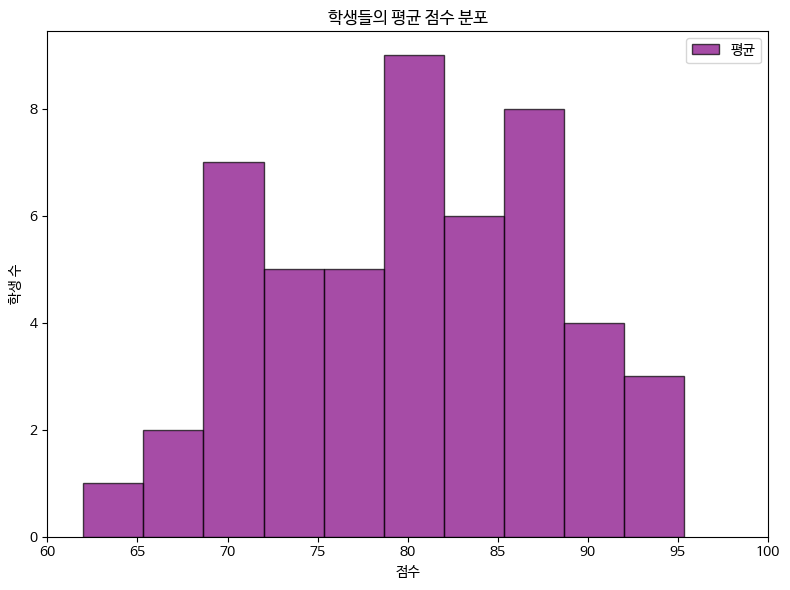

In [ ]:
# 평균 당 사람 수 찾기 & 서브플롯 생성
avg = grade["평균"]
fig, axes = plt.subplots(figsize=(8, 6), sharey=True)
#평균 그래프 만들기
plt.hist(avg, bins=10, color='purple', alpha=0.7, label='평균', edgecolor = "black")
plt.title("학생들의 평균 점수 분포")
plt.xlim(60, 100)
plt.xlabel("점수")
plt.ylabel("학생 수")
plt.legend()

plt.tight_layout()
plt.show()
